# Completude do conjunto de genes de *Colletotrichum abscissum* Ca142 (BUSCO)

**Montagem:** GCA_023376855.1 ·

**Linhagem:** Ca142 ·

**Anotação:** 15.499 genes codificadores de proteína (MAKER)

Os cadernos anteriores mostraram que a anotação é internamente consistente. Falta a pergunta complementar: **ela
está completa?** Os genes que todo fungo desse grupo deveria ter estão lá?

1. O que é o BUSCO
2. Preparação: ambiente conda próprio
3. Configuração e escolha do conjunto de referência
4. Execução
5. Resultado
6. BUSCOs e a qualidade dos modelos de genes
7. Tabelas salvas
8. Síntese

**Pré-requisitos:** ter executado `03_estrutura_ca142.ipynb` e ter o BUSCO instalado (seção 2). Este é o único
caderno da série que depende de um programa externo e de um download adicional (o conjunto de referência, com algumas
centenas de MB).

## 1. O que é o BUSCO

**BUSCO** (*Benchmarking Universal Single-Copy Orthologs*) mede a completude de um genoma ou de uma anotação
procurando genes que **deveriam** estar presentes.

- A partir do banco OrthoDB, os autores selecionaram, para cada grupo taxonômico, os genes presentes **em cópia
  única em quase todas as espécies** do grupo. Cada um desses genes é um "BUSCO".
- Para cada BUSCO há um modelo estatístico (um perfil HMM) construído a partir das proteínas das várias espécies.
- O programa procura cada perfil nas proteínas da nossa anotação e classifica o resultado:

| Classe | Significado |
|---|---|
| **C**ompleto e em cópia única (**S**) | encontrado uma vez, com o tamanho esperado |
| **C**ompleto e **D**uplicado (D) | encontrado mais de uma vez |
| **F**ragmentado (F) | encontrado, mas incompleto (mais curto que o esperado) |
| Ausente (**M**, de *missing*) | não encontrado |

O resultado é resumido numa linha como `C:98.5%[S:98.0%,D:0.5%],F:0.5%,M:1.0%,n:3817`.

**Dois modos.** No modo **proteínas**, usado aqui, o BUSCO avalia a **anotação**: um gene ausente pode estar no
genoma e não ter sido anotado. No modo **genoma**, ele procura os genes direto na sequência e avalia a **montagem**.
O artigo da Ca142 relata mais de 98% de completude da montagem (BUSCO v3, conjunto `sordariomyceta_odb9`).

**Por que isso importa para o RNAi:** genes conservados e de cópia única costumam ter funções básicas da célula.
São bons pontos de partida para procurar alvos essenciais, e um alvo de cópia única não tem um parálogo que possa
compensar o silenciamento.

## 2. Preparação: ambiente conda próprio

O BUSCO tem muitas dependências (HMMER, miniprot, Augustus…). Para não mexer no ambiente dos cadernos, ele fica em
um ambiente separado, chamado `busco`. No **terminal**, uma única vez:

```bash
conda create -n busco -c conda-forge -c bioconda "busco>=6"
```

**Atenção ao `"busco>=6"`.** Sem exigir a versão, o conda pode instalar uma versão muito antiga (3.0.2), incompatível
com os conjuntos de referência atuais. Foi o que aconteceu no teste deste caderno. Confira com:

```bash
conda run -n busco busco --version      # deve mostrar BUSCO 6.x
```

O caderno chama o BUSCO desse ambiente com `conda run -n busco busco …`, sem que você precise ativá-lo.

## 3. Configuração

A célula define os caminhos e localiza o BUSCO. A função `localizar_busco` tenta, nesta ordem:

1. o ambiente conda `busco` (via `conda run`);
2. um `busco` já disponível no ambiente atual.

Se nenhum for encontrado, a célula para com uma mensagem explicando o que fazer.

In [1]:
import json
import os
import re
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ACCESSION = "GCA_023376855.1"
ENV_BUSCO = "busco"                 # nome do ambiente conda onde o BUSCO está instalado
NOME_EXECUCAO = "ca142_proteinas"   # nome da pasta de resultados

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DADOS = RAIZ / "data" / "raw" / "ca142" / "ncbi_dataset" / "data" / ACCESSION
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_BUSCO = RAIZ / "results" / "busco"                  # resultados do BUSCO
DIR_REF = RAIZ / "data" / "raw" / "busco_downloads"     # conjuntos de referência baixados
for d in (DIR_FIG, DIR_BUSCO, DIR_REF):
    d.mkdir(parents=True, exist_ok=True)

ARQ_PROT = DIR_DADOS / "protein.faa"
ARQ_GENES = DIR_PROC / "ca142_genes.tsv"
assert ARQ_GENES.exists(), "Rode antes o caderno 03_estrutura_ca142.ipynb (ele gera ca142_genes.tsv)."

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (7.5, 3.2), "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "xtick.labelsize": 9, "ytick.labelsize": 9, "font.size": 10,
})

def fmt(n):
    return f"{n:,.0f}".replace(",", ".")

def localizar_busco():
    """Devolve (comando, versão) para chamar o BUSCO, ou (None, None) se não encontrar."""
    candidatos = []
    conda = os.environ.get("CONDA_EXE") or shutil.which("conda")
    if not conda:
        for pasta in ("anaconda3", "miniconda3", "miniforge3"):
            caminho = Path.home() / pasta / "bin" / "conda"
            if caminho.exists():
                conda = str(caminho)
                break
    if conda:
        candidatos.append([conda, "run", "--no-capture-output", "-n", ENV_BUSCO, "busco"])
    if shutil.which("busco"):
        candidatos.append(["busco"])
    for cmd in candidatos:
        try:
            r = subprocess.run(cmd + ["--version"], capture_output=True, text=True, timeout=120)
        except (OSError, subprocess.TimeoutExpired):
            continue
        m = re.search(r"BUSCO\s+(\d+(?:\.\d+)*)", r.stdout + r.stderr)
        if r.returncode == 0 and m:
            return cmd, m.group(1)
    return None, None

CMD_BUSCO, VERSAO_BUSCO = localizar_busco()
if CMD_BUSCO is None:
    raise RuntimeError('BUSCO não encontrado. No terminal: conda create -n busco -c conda-forge -c bioconda "busco>=6"')
print("BUSCO", VERSAO_BUSCO, "·", " ".join(CMD_BUSCO))
if int(VERSAO_BUSCO.split(".")[0]) < 5:
    raise RuntimeError(f'BUSCO {VERSAO_BUSCO} é antigo demais. Recrie o ambiente exigindo a versão: "busco>=6".')

BUSCO 6.1.0 · /home/denilson/anaconda3/bin/conda run --no-capture-output -n busco busco


### 3.1 Escolha do conjunto de referência (linhagem)

O BUSCO tem um conjunto de genes para cada grupo taxonômico. Quanto **mais específico** o grupo, mais genes o
conjunto tem e mais sensível é o teste. Para *Colletotrichum*, do mais específico ao mais geral:

`glomerellales` (ordem) → `sordariomycetes` (classe) → `ascomycota` (filo) → `fungi` (reino)

A célula pede ao BUSCO a lista de conjuntos disponíveis e escolhe o mais específico que existir. O nome é passado
**sem o sufixo de versão** (`_odb12` etc.); o BUSCO acrescenta a versão padrão dele.

Para forçar outra escolha, defina `LINHAGEM` à mão no fim da célula (por exemplo, `LINHAGEM = "ascomycota"`).

In [2]:
PREFERENCIA = ["glomerellales", "sordariomycetes", "ascomycota", "fungi"]

try:
    r = subprocess.run(CMD_BUSCO + ["--list-datasets", "--download_path", str(DIR_REF)],
                       capture_output=True, text=True, cwd=DIR_BUSCO, timeout=300)
    lista = r.stdout
except subprocess.TimeoutExpired:
    lista = ""
disponiveis = sorted(set(re.findall(r"([a-z0-9]+)_odb\d+", lista)))
print(f"Conjuntos disponíveis: {len(disponiveis)}")
for linha in lista.splitlines():
    if any(nome in linha for nome in PREFERENCIA):
        print("  ", linha.strip())

LINHAGEM = next((nome for nome in PREFERENCIA if nome in disponiveis), "sordariomycetes")
if not disponiveis:
    print("Não foi possível obter a lista (sem internet?). Usando o padrão.")
print("\nLinhagem escolhida:", LINHAGEM)

Conjuntos disponíveis: 526
   - fungi_odb12.2 [1019]
   - ascomycota_odb12.2 [2557]
   - sordariomycetes_odb12.2 [3876]
   - glomerellales_odb12.2 [5942]

Linhagem escolhida: glomerellales


**Resultado:** o BUSCO 6.1 oferece 526 conjuntos de referência. Os quatro candidatos existem, e o número entre
colchetes é a quantidade de genes de cada um: `fungi` (1.019), `ascomycota` (2.557), `sordariomycetes` (3.876) e
`glomerellales` (5.942). Foi escolhido o **`glomerellales`**, o mais específico: quase seis vezes mais genes que o
conjunto geral de fungos.

## 4. Execução

O comando equivalente no terminal é:

```bash
busco -i protein.faa -m proteins -l <linhagem> -o ca142_proteinas --out_path results/busco \
      --download_path data/raw/busco_downloads -c <núcleos> --opt-out-run-stats
```

| Opção | Significado |
|---|---|
| `-i` | arquivo de entrada (as 15.499 proteínas) |
| `-m proteins` | modo proteínas: avalia a anotação |
| `-l` | conjunto de referência |
| `-o`, `--out_path` | nome e pasta dos resultados |
| `--download_path` | onde guardar o conjunto de referência baixado |
| `-c` | número de núcleos do processador |
| `--opt-out-run-stats` | não enviar estatísticas de uso aos autores (o BUSCO 6 envia por padrão) |

Na primeira execução, o BUSCO baixa o conjunto de referência. Depois compara cada perfil com as proteínas; no modo
proteínas isso leva de alguns minutos a algumas dezenas de minutos, conforme o computador e o tamanho do conjunto.

Se os resultados já existirem, a célula **não roda o BUSCO de novo**. Para refazer, apague a pasta
`results/busco/ca142_proteinas`.

In [3]:
def pasta_resultado():
    """Pasta run_<linhagem> com os resultados, se existir."""
    pastas = sorted((DIR_BUSCO / NOME_EXECUCAO).glob("run_*/full_table.tsv"))
    return pastas[0].parent if pastas else None

if pasta_resultado():
    print("Resultados já existem; BUSCO não foi executado de novo.")
else:
    nucleos = max(1, min(8, (os.cpu_count() or 2) - 1))
    cmd = CMD_BUSCO + ["-i", str(ARQ_PROT), "-m", "proteins", "-l", LINHAGEM, "-o", NOME_EXECUCAO,
                       "--out_path", str(DIR_BUSCO), "--download_path", str(DIR_REF),
                       "-c", str(nucleos), "--opt-out-run-stats"]
    print("Executando:", " ".join(cmd), "\n")
    with subprocess.Popen(cmd, cwd=DIR_BUSCO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as proc:
        for linha in proc.stdout:
            if "INFO" in linha or "ERROR" in linha or "WARNING" in linha or "|" in linha:
                print(linha.rstrip())
    if proc.returncode != 0 or not pasta_resultado():
        raise RuntimeError("O BUSCO terminou com erro. Veja as mensagens acima e results/busco/ca142_proteinas/logs/.")

DIR_RUN = pasta_resultado()
print("\nResultados em:", DIR_RUN.relative_to(RAIZ))

Executando: /home/denilson/anaconda3/bin/conda run --no-capture-output -n busco busco -i /home/denilson/rep/dfb/cabs/data/raw/ca142/ncbi_dataset/data/GCA_023376855.1/protein.faa -m proteins -l glomerellales -o ca142_proteinas --out_path /home/denilson/rep/dfb/cabs/results/busco --download_path /home/denilson/rep/dfb/cabs/data/raw/busco_downloads -c 7 --opt-out-run-stats 

2026-11-14 20:57:06 INFO:	***** Start a BUSCO v6.1.0 analysis, current time: 11/14/2026 20:57:06 *****
2026-11-14 20:57:06 INFO:	Configuring BUSCO with local environment
2026-11-14 20:57:06 INFO:	Running proteins mode
2026-11-14 20:57:06 INFO:	Downloading information on latest versions of BUSCO data...
2026-11-14 20:57:08 INFO:	Input file is /home/denilson/rep/dfb/cabs/data/raw/ca142/ncbi_dataset/data/GCA_023376855.1/protein.faa
2026-11-14 20:57:08 INFO:	Downloading file 'https://busco-data.ezlab.org/v5/data/lineages/glomerellales_odb12.2.2026-05-13.tar.gz'
2026-11-14 20:59:02 INFO:	Decompressing file '/home/denilson/

**Resultado:** o BUSCO baixou o conjunto `glomerellales_odb12.2` (versão de 13/05/2026), comparou os 5.942 perfis com
as 15.499 proteínas e terminou em 880 segundos, cerca de 15 minutos. O resumo aparece no quadro ao fim da saída e é
analisado na seção 5.

## 5. Resultado

O BUSCO grava em `run_<linhagem>/` a tabela `full_table.tsv`, com uma linha por BUSCO (ou mais de uma, quando o
BUSCO está duplicado):

| Coluna | Conteúdo |
|---|---|
| `Busco id` | identificador do gene de referência no OrthoDB |
| `Status` | `Complete` (completo, cópia única), `Duplicated`, `Fragmented` ou `Missing` |
| `Sequence` | a proteína da nossa anotação que corresponde ao BUSCO (o `protein_id`) |
| `Score`, `Length` | pontuação e comprimento do alinhamento |
| `OrthoDB url`, `Description` | link e descrição do gene de referência |

Lemos a tabela e contamos os BUSCOs em cada classe. Cada BUSCO é contado uma vez, mesmo que apareça em várias linhas.

In [4]:
COLUNAS = ["busco_id", "status", "protein_id", "score", "tamanho", "url", "descricao"]
linhas = []
with open(DIR_RUN / "full_table.tsv") as f:
    for linha in f:
        if linha.startswith("#") or not linha.strip():
            continue
        campos = linha.rstrip("\n").split("\t")
        linhas.append((campos + [None] * len(COLUNAS))[:len(COLUNAS)])     # linhas "Missing" só têm 2 campos
busco = pd.DataFrame(linhas, columns=COLUNAS)
busco["score"] = pd.to_numeric(busco["score"])
busco["tamanho"] = pd.to_numeric(busco["tamanho"])

ROTULOS = {"Complete": "Completos, cópia única (S)", "Duplicated": "Completos, duplicados (D)",
           "Fragmented": "Fragmentados (F)", "Missing": "Ausentes (M)"}
por_busco = busco.drop_duplicates("busco_id").set_index("busco_id")["status"]
n_total = len(por_busco)
resumo = por_busco.value_counts().reindex(ROTULOS.keys(), fill_value=0).rename(index=ROTULOS).to_frame("BUSCOs")
resumo["%"] = (100 * resumo["BUSCOs"] / n_total).round(1)
completos_pct = resumo["%"].iloc[:2].sum()

arq_json = DIR_RUN / "short_summary.json"
if arq_json.exists():
    info = json.loads(arq_json.read_text())
    print("Conjunto de referência:", info.get("lineage_dataset", {}).get("name"),
          "· criado em", info.get("lineage_dataset", {}).get("creation_date"))
    print("Resumo do BUSCO:       ", info.get("results", {}).get("one_line_summary"))
print(f"BUSCOs avaliados: {fmt(n_total)}  ·  completos (S + D): {completos_pct:.1f}%")
resumo

Conjunto de referência: glomerellales_odb12.2 · criado em 2026-05-13
Resumo do BUSCO:        C:98.3%[S:98.2%,D:0.1%],F:0.2%,M:1.5%,n:5942
BUSCOs avaliados: 5.942  ·  completos (S + D): 98.3%


,BUSCOs,%
status,,
"Completos, cópia única (S)",5835,98.2
"Completos, duplicados (D)",7,0.1
Fragmentados (F),13,0.2
Ausentes (M),87,1.5


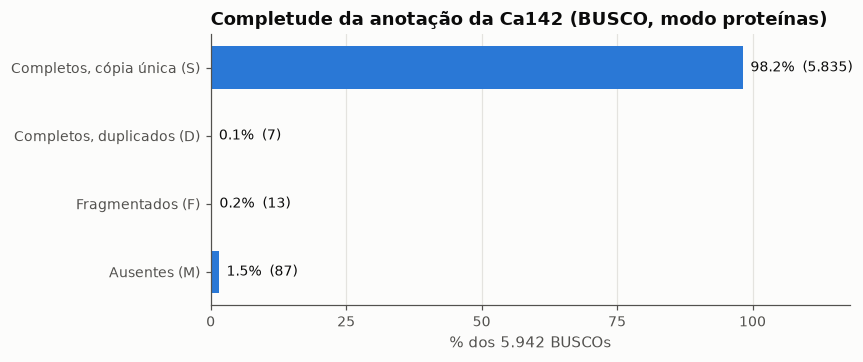

In [5]:
fig, ax = plt.subplots()
y = np.arange(len(resumo))[::-1]
ax.barh(y, resumo["%"], color=AZUL, height=0.62)
for yi, (n, p) in zip(y, zip(resumo["BUSCOs"], resumo["%"])):
    ax.annotate(f"{p:.1f}%  ({fmt(n)})", (p, yi), xytext=(5, 0), textcoords="offset points",
                va="center", color=TINTA, fontsize=9)
ax.set_yticks(y, resumo.index)
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel(f"% dos {fmt(n_total)} BUSCOs")
ax.set_title("Completude da anotação da Ca142 (BUSCO, modo proteínas)")
ax.grid(axis="y", visible=False)
fig.savefig(DIR_FIG / "05_busco.png", bbox_inches="tight")
plt.show()

**Resultado: a anotação tem 98,3% dos genes conservados da ordem Glomerellales.**

| Classe | BUSCOs | % |
|---|---|---|
| Completos, cópia única (S) | 5.835 | 98,2% |
| Completos, duplicados (D) | 7 | 0,1% |
| Fragmentados (F) | 13 | 0,2% |
| Ausentes (M) | 87 | 1,5% |

- **Completos: 5.842 de 5.942 (98,3%).** A anotação é completa quanto aos genes conservados. O valor concorda com o
  do artigo (mais de 98% para a montagem), embora os dois não sejam diretamente comparáveis: aqui o conjunto de
  referência é mais novo e maior, e o modo é o de proteínas.
- **Duplicados: só 7 (0,1%).** Não há sinal de genes anotados em dobro nem de sequências redundantes na montagem. Os
  7 BUSCOs duplicados correspondem a 18 genes e parecem pequenas famílias reais: uma calpaína com 5 cópias, uma
  proteína com domínio Piwi com 3, e cinco outros com 2 cópias cada. As proteínas com domínio Piwi são as
  Argonautas, peças centrais da maquinaria de RNAi; o caderno 06 volta a elas.
- **Fragmentados: só 13 (0,2%).** Os problemas de modelo vistos no caderno 03 quase nunca chegam a truncar um gene
  conservado.
- **Ausentes: 87 (1,5%).** Podem faltar no genoma ou só na anotação. Para distinguir, existe o modo genoma (comando
  ao fim do caderno). Com 1,5%, a resposta não muda a conclusão.

Como a anotação tem uma proteína por gene, as 5.953 linhas da tabela são os 5.942 BUSCOs mais as 11 cópias extras
dos duplicados.

## 6. BUSCOs e a qualidade dos modelos de genes

Ligamos cada BUSCO encontrado ao gene da nossa tabela (pelo `protein_id`) e cruzamos com os dois sinais de problema
do caderno 03: genes **parciais** e genes com **íntrons não canônicos**.

A pergunta: os BUSCOs fragmentados são os genes que já sabíamos ter modelo duvidoso?

In [6]:
genes = pd.read_csv(ARQ_GENES, sep="\t")
if "n_introns_nc" not in genes.columns:
    raise RuntimeError("ca142_genes.tsv está desatualizado: rode de novo o caderno 03 (versão revisada).")

achados = busco.dropna(subset=["protein_id"]).sort_values("score", ascending=False).drop_duplicates("protein_id")
genes_busco = genes.merge(achados[["protein_id", "busco_id", "status", "score", "descricao"]],
                          on="protein_id", how="left").rename(columns={"status": "busco_status"})

n_ligados = genes_busco["busco_id"].notna().sum()
print(f"Genes da Ca142 ligados a um BUSCO: {fmt(n_ligados)} de {fmt(len(genes))} "
      f"({100 * n_ligados / len(genes):.1f}%)")

com = genes_busco.dropna(subset=["busco_id"])
cruz = com.groupby("busco_status").agg(
    genes=("locus_tag", "size"),
    parciais=("parcial", "sum"),
    com_intron_nao_canonico=("n_introns_nc", lambda s: int((s > 0).sum())),
    proteina_mediana=("tam_proteina", "median"))
cruz["% parciais"] = (100 * cruz["parciais"] / cruz["genes"]).round(1)
cruz["% com íntron não canônico"] = (100 * cruz["com_intron_nao_canonico"] / cruz["genes"]).round(1)
cruz = cruz.rename(index=ROTULOS, columns={"proteina_mediana": "proteína mediana (aa)"})
cruz[["genes", "% parciais", "% com íntron não canônico", "proteína mediana (aa)"]]

Genes da Ca142 ligados a um BUSCO: 5.866 de 15.499 (37.8%)


,genes,% parciais,% com íntron não canônico,proteína mediana (aa)
busco_status,,,,
"Completos, cópia única (S)",5835,1.5,5.7,480.0
"Completos, duplicados (D)",18,0.0,0.0,473.5
Fragmentados (F),13,7.7,15.4,482.0


**Resultado**

- **5.866 genes da Ca142 (37,8%) correspondem a um BUSCO.** É o conjunto de genes conservados da anotação. A
  proteína mediana deles tem 480 aa, contra 393 aa no proteoma inteiro: genes conservados tendem a ser mais longos.
- **Os alertas de modelo aparecem nos genes conservados na mesma proporção que no resto.** Entre os 5.835 genes de
  BUSCOs completos, 1,5% são parciais (no genoma todo, 1,4%) e 5,7% têm íntron não canônico (no genoma todo, 7,2%).
  Ser conservado não protege um gene de ter um modelo imperfeito.
- **Mesmo assim, o BUSCO os considera completos.** Cerca de 90 genes parciais e 330 genes com íntron não canônico
  alinham com o perfil do gene conservado do começo ao fim. Isso mede o tamanho do defeito: falta ou sobra um trecho
  curto, e não uma parte grande da proteína. Os alertas indicam **incerteza local na sequência**, não genes
  quebrados.
- **Os 13 fragmentados não se explicam pelos alertas.** Só 1 é parcial e 2 têm íntron não canônico. A maioria tem um
  modelo sem nenhum alerta e, ainda assim, mais curto que o esperado. Com 13 genes, as porcentagens da tabela (7,7% e
  15,4%) são instáveis e não sustentam conclusões.

**Um uso extra desta tabela: nomes para proteínas hipotéticas.** Cada BUSCO traz a descrição do gene no OrthoDB. Das
8.229 proteínas hipotéticas da Ca142, 1.967 correspondem a um BUSCO, e cerca de 1.600 delas ganham assim uma descrição
informativa (calculado na revisão, com as tabelas salvas). O caderno 06 usa essa descrição para achar genes que a
busca por nome de produto não encontra.

## 7. Tabelas salvas

| Arquivo | Uma linha por | Conteúdo |
|---|---|---|
| `ca142_busco.tsv` | BUSCO (ou cópia) | a `full_table` do BUSCO, com nomes de colunas simples |
| `ca142_genes_busco.tsv` | gene ligado a um BUSCO | `locus_tag`, BUSCO correspondente, classe, pontuação e descrição |

A segunda tabela é usada no caderno `06_sintese_ca142.ipynb`.

In [7]:
busco.to_csv(DIR_PROC / "ca142_busco.tsv", sep="\t", index=False)
saida = genes_busco.dropna(subset=["busco_id"])[["locus_tag", "protein_id", "busco_id", "busco_status", "score", "descricao"]]
saida.to_csv(DIR_PROC / "ca142_genes_busco.tsv", sep="\t", index=False)
print(f"ca142_busco.tsv        {fmt(len(busco)):>7s} linhas")
print(f"ca142_genes_busco.tsv  {fmt(len(saida)):>7s} linhas")

ca142_busco.tsv          5.953 linhas
ca142_genes_busco.tsv    5.866 linhas


## 8. Síntese

In [8]:
unica = genes_busco["busco_status"] == "Complete"
confiaveis = unica & ~genes_busco["parcial"] & (genes_busco["n_introns_nc"] == 0)
sintese = pd.Series(dtype="object", data={
    "BUSCO": VERSAO_BUSCO,
    "Conjunto de referência": DIR_RUN.name.removeprefix("run_"),
    "BUSCOs avaliados": fmt(n_total),
    "Completos (S + D)": f"{completos_pct:.1f}%",
    "  cópia única (S)": f"{resumo['%'].iloc[0]:.1f}%",
    "  duplicados (D)": f"{resumo['%'].iloc[1]:.1f}%",
    "Fragmentados (F)": f"{resumo['%'].iloc[2]:.1f}%",
    "Ausentes (M)": f"{resumo['%'].iloc[3]:.1f}%",
    "Genes ligados a um BUSCO": fmt(n_ligados),
    "  de cópia única e sem alertas de modelo": fmt(confiaveis.sum()),
})
sintese.to_frame("Ca142")

,Ca142
BUSCO,6.1.0
Conjunto de referência,glomerellales_odb12.2
BUSCOs avaliados,5.942
Completos (S + D),98.3%
cópia única (S),98.2%
duplicados (D),0.1%
Fragmentados (F),0.2%
Ausentes (M),1.5%
Genes ligados a um BUSCO,5.866
de cópia única e sem alertas de modelo,5.417


**Resultado da síntese:** 98,3% de completude, com 5.866 genes ligados a um BUSCO. Desses, **5.417 são de cópia
única, completos e sem íntron não canônico**: o núcleo mais sólido da anotação, e um bom ponto de partida para a
busca de alvos.

**Para distinguir "ausente no genoma" de "ausente na anotação"**

Os 87 BUSCOs ausentes (1,5%) são poucos, e esta etapa é opcional. Se quiser saber se eles faltam no genoma ou só na
anotação, rode o modo genoma no terminal (demora mais, porque o BUSCO precisa predizer os genes na sequência):

```bash
cd results/busco
conda run --no-capture-output -n busco busco -i ../../data/raw/ca142/ncbi_dataset/data/GCA_023376855.1/GCA_023376855.1_CABS01_v0.1_genomic.fna \
    -m genome -l glomerellales -o ca142_genoma --download_path ../../data/raw/busco_downloads -c 8 --opt-out-run-stats
```

Um BUSCO ausente no modo proteínas e completo no modo genoma é um gene que existe na Ca142 e **não foi anotado**.
(Este comando não foi executado na preparação do caderno; as opções foram conferidas na ajuda do BUSCO 6.1.)

**Limitações**

- O BUSCO só avalia genes conservados. Ele não diz nada sobre os genes específicos da espécie, que incluem muitos
  dos genes de virulência.
- A porcentagem depende do conjunto de referência. Ao comparar montagens ou anotações, use sempre o mesmo conjunto.

**Próximo caderno:** `06_sintese_ca142.ipynb` reúne os resultados e monta a tabela final de genes.